<a href="https://colab.research.google.com/github/Ramyashree-BR/customer-churn-prediction/blob/main/notebooks/churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
churn_percentage = df["Churn Label"].value_counts(normalize=True) * 100

print(churn_percentage)

Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [ ]:
manual_customer = {
    "Gender": "Male",
    "Senior Citizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "Tenure Months": 5,
    "Phone Service": "Yes",
    "Multiple Lines": "No",
    "Internet Service": "Fiber optic",
    "Online Security": "No",
    "Online Backup": "No",
    "Device Protection": "No",
    "Tech Support": "No",
    "Streaming TV": "Yes",
    "Streaming Movies": "Yes",
    "Contract": "Month-to-month",
    "Paperless Billing": "Yes",
    "Payment Method": "Electronic check",
    "Monthly Charges": 85.0,
    "Total Charges": 425.0
}

result, probability = predict_churn(manual_customer)

print("Customer Churn Prediction")
print("-------------------------")
print("Prediction:", result)
print("Churn Probability:", round(probability * 100, 2), "%")

Customer Churn Prediction
-------------------------
Prediction: No - Customer is unlikely to churn
Churn Probability: 19.44 %


In [ ]:
sample_customer = df_model.drop("Churn Value", axis=1).iloc[0].to_dict()

result, probability = predict_churn(sample_customer)

print("Prediction:", result)
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Yes - Customer is likely to churn
Churn Probability: 53.02 %


In [ ]:
def predict_churn(customer_data):
    # Convert input into DataFrame
    customer_df = pd.DataFrame([customer_data])

    # Convert Total Charges to numeric
    customer_df["Total Charges"] = pd.to_numeric(
        customer_df["Total Charges"],
        errors="coerce"
    )

    # Fill missing Total Charges
    customer_df["Total Charges"] = customer_df["Total Charges"].fillna(
        df_model["Total Charges"].median()
    )

    # Convert categorical variables
    customer_df = pd.get_dummies(customer_df, drop_first=True)

    # Make sure the columns match training data
    customer_df = customer_df.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Prediction
    prediction = best_dt.predict(customer_df)[0]

    # Probability
    probability = best_dt.predict_proba(customer_df)[0][1]

    if prediction == 1:
        result = "Yes - Customer is likely to churn"
    else:
        result = "No - Customer is unlikely to churn"

    return result, probability

In [ ]:
joblib.dump(X_train.columns.tolist(), "../model_features.pkl")

print("Feature columns saved successfully!")

Feature columns saved successfully!


In [ ]:
import joblib

# Save the trained model
joblib.dump(best_dt, "../best_churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


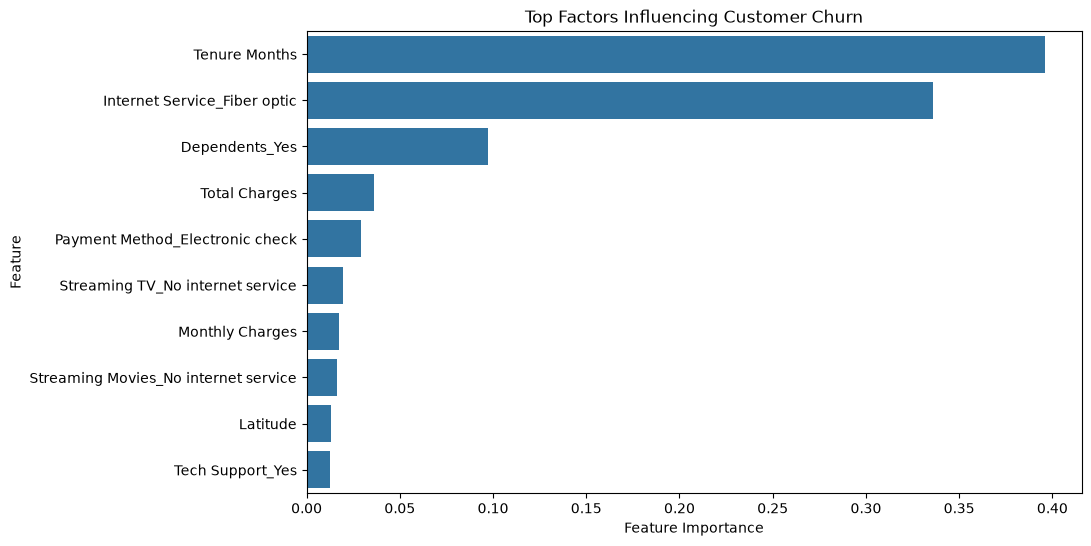

In [ ]:
plt.figure(figsize=(10, 6))

top_features_dt = feature_importance_dt.head(10)

sns.barplot(
    data=top_features_dt,
    x="Importance",
    y="Feature"
)

plt.title("Top Factors Influencing Customer Churn")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.show()

In [ ]:
# Get feature importance from the tuned Decision Tree

feature_importance_dt = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_dt.feature_importances_
})

# Sort from highest to lowest
feature_importance_dt = feature_importance_dt.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_dt.head(15))

                                 Feature  Importance
2                          Tenure Months    0.395874
13          Internet Service_Fiber optic    0.336069
9                         Dependents_Yes    0.097360
4                          Total Charges    0.036394
31       Payment Method_Electronic check    0.029388
23      Streaming TV_No internet service    0.019427
3                        Monthly Charges    0.017139
25  Streaming Movies_No internet service    0.016335
0                               Latitude    0.013022
22                      Tech Support_Yes    0.012667
28                     Contract_Two year    0.009898
8                            Partner_Yes    0.009802
10                     Phone Service_Yes    0.006626
7                     Senior Citizen_Yes    0.000000
6                            Gender_Male    0.000000


Confusion Matrix:
[[870 165]
 [133 241]]


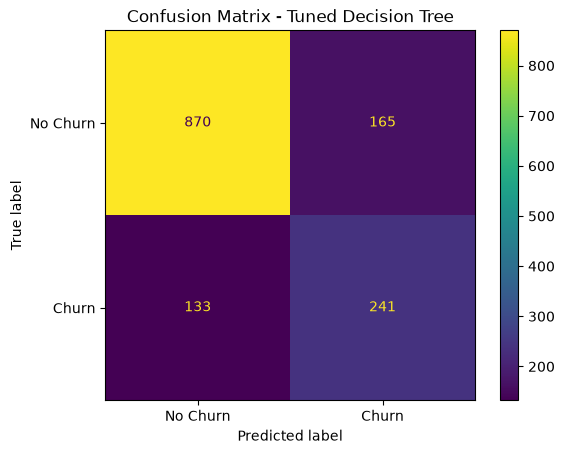

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm_best = confusion_matrix(y_test, y_pred_best)

print("Confusion Matrix:")
print(cm_best)

# Plot
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_best,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Tuned Decision Tree")
plt.show()

In [ ]:
print("Logistic Regression ROC-AUC:", auc)
print("Tuned Decision Tree ROC-AUC:", auc_dt)

Logistic Regression ROC-AUC: 0.8488491048593352
Tuned Decision Tree ROC-AUC: 0.8334160014466919


Tuned Decision Tree ROC-AUC: 0.8334160014466919


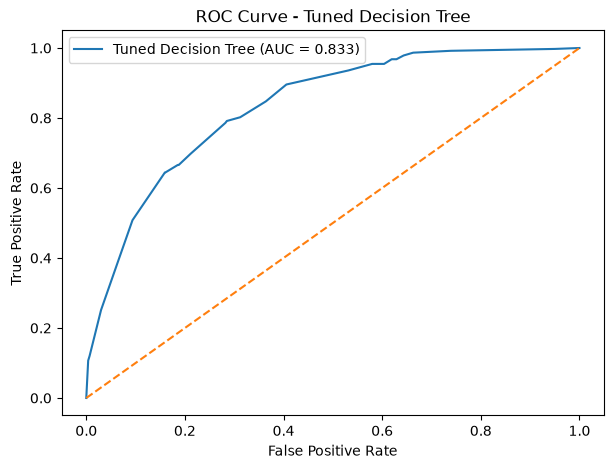

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Probability of churn
y_prob_dt = best_dt.predict_proba(X_test)[:, 1]

# ROC-AUC
auc_dt = roc_auc_score(y_test, y_prob_dt)

print("Tuned Decision Tree ROC-AUC:", auc_dt)

# ROC curve
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Tuned Decision Tree (AUC = {auc_dt:.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Decision Tree")
plt.legend()
plt.show()

In [ ]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Tuned Decision Tree"
    ],
    "Accuracy": [
        accuracy,
        accuracy_dt,
        accuracy_best
    ],
    "Precision": [
        precision,
        precision_dt,
        precision_best
    ],
    "Recall": [
        recall,
        recall_dt,
        recall_best
    ],
    "F1-Score": [
        f1,
        f1_dt,
        f1_best
    ]
})

final_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.804,0.648,0.572,0.608
1,Decision Tree,0.787,0.591,0.644,0.616
2,Tuned Decision Tree,0.789,0.594,0.644,0.618


In [ ]:
# Predictions
y_pred_best = best_dt.predict(X_test)

# Evaluation
accuracy_best = accuracy_score(y_test, y_pred_best)
precision_best = precision_score(y_test, y_pred_best)
recall_best = recall_score(y_test, y_pred_best)
f1_best = f1_score(y_test, y_pred_best)

print("Tuned Decision Tree Evaluation")
print("------------------------------")
print("Accuracy :", accuracy_best)
print("Precision:", precision_best)
print("Recall   :", recall_best)
print("F1-Score :", f1_best)

Tuned Decision Tree Evaluation
------------------------------
Accuracy : 0.7885024840312278
Precision: 0.5935960591133005
Recall   : 0.6443850267379679
F1-Score : 0.617948717948718


In [ ]:
# Create the tuned Decision Tree
best_dt = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=2,
    min_samples_split=10,
    random_state=42
)

# Train the tuned model
best_dt.fit(X_train, y_train)

print("Tuned Decision Tree trained successfully!")

Tuned Decision Tree trained successfully!


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

# Parameters to test
param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Create Decision Tree
dt = DecisionTreeClassifier(random_state=42)

# Grid Search
grid_search = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and search for the best parameters
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 2, 'min_samples_split': 10}

Best Cross-Validation F1-Score:
0.5576355854705055


In [ ]:
model_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.804,0.648,0.572,0.608
1,Decision Tree,0.787,0.591,0.644,0.616


In [ ]:
# Compare model performance

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [accuracy, accuracy_dt],
    "Precision": [precision, precision_dt],
    "Recall": [recall, recall_dt],
    "F1-Score": [f1, f1_dt]
})

print(model_comparison)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.804116   0.648485  0.572193  0.607955
1        Decision Tree  0.787083   0.590686  0.644385  0.616368


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Decision Tree Evaluation")
print("------------------------")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1-Score :", f1_dt)

Decision Tree Evaluation
------------------------
Accuracy : 0.78708303761533
Precision: 0.5906862745098039
Recall   : 0.6443850267379679
F1-Score : 0.6163682864450127


In [ ]:
y_pred_dt = decision_tree.predict(X_test)

print("Decision Tree predictions completed!")

Decision Tree predictions completed!


In [ ]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree = DecisionTreeClassifier(
    random_state=42,
    max_depth=5
)

# Train the model
decision_tree.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


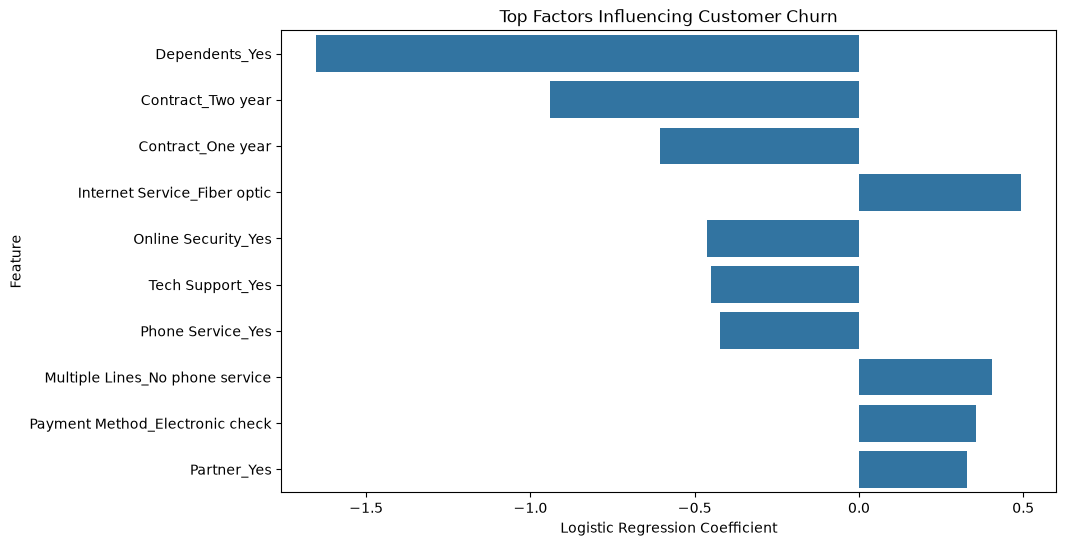

In [ ]:
plt.figure(figsize=(10, 6))

top_features = feature_importance.head(10)

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top Factors Influencing Customer Churn")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.show()

In [ ]:
# Get feature coefficients
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})

# Absolute coefficient shows strength of influence
feature_importance["Importance"] = feature_importance["Coefficient"].abs()

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                            Feature  Coefficient  Importance
9                    Dependents_Yes    -1.651134    1.651134
28                Contract_Two year    -0.939868    0.939868
27                Contract_One year    -0.604384    0.604384
13     Internet Service_Fiber optic     0.493235    0.493235
16              Online Security_Yes    -0.463082    0.463082
22                 Tech Support_Yes    -0.450594    0.450594
10                Phone Service_Yes    -0.421554    0.421554
11  Multiple Lines_No phone service     0.405779    0.405779
31  Payment Method_Electronic check     0.355054    0.355054
8                       Partner_Yes     0.329825    0.329825
29            Paperless Billing_Yes     0.321467    0.321467
12               Multiple Lines_Yes     0.262458    0.262458
18                Online Backup_Yes    -0.194611    0.194611
20            Device Protection_Yes    -0.127254    0.127254
24                 Streaming TV_Yes     0.110303    0.110303


ROC-AUC Score: 0.8488491048593352


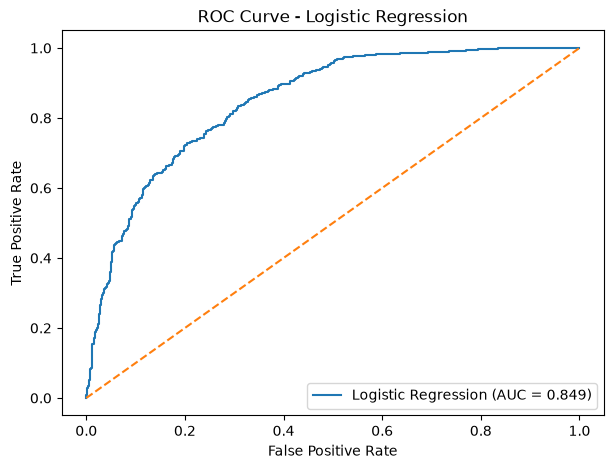

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Get probability of churn
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
auc = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

Confusion Matrix:
[[919 116]
 [160 214]]


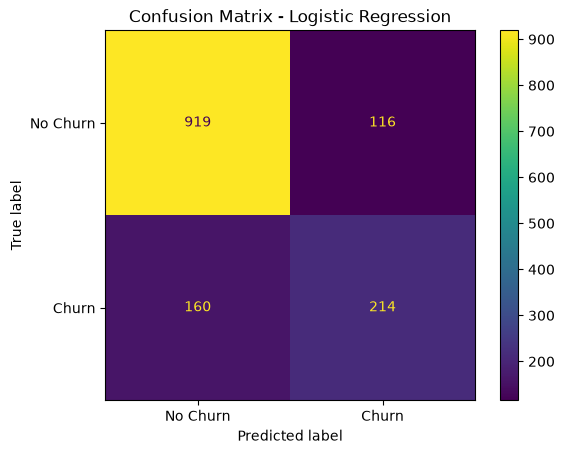

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Model Evaluation Results
------------------------
Accuracy : 0.8041163946061036
Precision: 0.6484848484848484
Recall   : 0.5721925133689839
F1-Score : 0.6079545454545454


In [ ]:
# Predict churn on test data
y_pred = logistic_model.predict(X_test)

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])

Predictions completed!
First 10 predictions: [0 1 0 0 0 1 0 0 0 0]


In [ ]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(max_iter=1000)

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


c:\Users\Rajanna\Documents\Customer Churn Prediction\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 33)
Testing data: (1409, 33)


In [ ]:
# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True)

print("Shape after encoding:", X.shape)
print("\nData types:")
print(X.dtypes.value_counts())

Shape after encoding: (7043, 33)

Data types:
bool       27
float64     4
int64       2
Name: count, dtype: int64


In [ ]:
df_model["Total Charges"] = df_model["Total Charges"].fillna(
    df_model["Total Charges"].median()
)

print("Missing values after cleaning:",
      df_model["Total Charges"].isnull().sum())

Missing values after cleaning: 0


In [ ]:
# Separate features and target
X = df_model.drop("Churn Value", axis=1)
y = df_model["Churn Value"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (7043, 22)
Target: (7043,)


In [ ]:
# Convert Total Charges from text to numeric
df_model["Total Charges"] = pd.to_numeric(
    df_model["Total Charges"],
    errors="coerce"
)

# Check missing values
print("Missing Total Charges:", df_model["Total Charges"].isnull().sum())

Missing Total Charges: 11


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 6562)
Testing data: (1409, 6562)


In [ ]:
print(X.dtypes.value_counts())

bool       6557
float64       3
int64         2
Name: count, dtype: int64


In [ ]:
print(X.shape)

(7043, 6562)


In [ ]:
X = pd.get_dummies(X, drop_first=True)

In [ ]:
X = df_model.drop("Churn Value", axis=1)
y = df_model["Churn Value"]

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7043, 22)
y shape: (7043,)


In [ ]:
df_model.dtypes

Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges            str
Churn Value            int64
CLTV                   int64
dtype: object

In [ ]:
df_model = df_model.drop([
    "CustomerID",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Churn Label",
    "Churn Score",
    "Churn Reason"
], axis=1)

In [ ]:
print(df_model.shape)

(7043, 23)


In [ ]:
print(df_model.columns.tolist())

['Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value', 'CLTV']


In [ ]:
df_model = df.copy()

In [ ]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df["Contract"], df["Churn Label"])

print(contingency_table)

Churn Label       No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [ ]:
if p_value < 0.05:
    print("There is a statistically significant relationship between Contract Type and Churn.")
else:
    print("There is no statistically significant relationship between Contract Type and Churn.")

There is a statistically significant relationship between Contract Type and Churn.


In [ ]:
chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("p-value:", p_value)

Chi-Square Statistic: 1184.5965720837926
p-value: 5.863038300673391e-258


In [ ]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(df["Contract"], df["Churn Label"])

print(contingency_table)

Churn Label       No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


<Axes: xlabel='Churn Label', ylabel='count'>

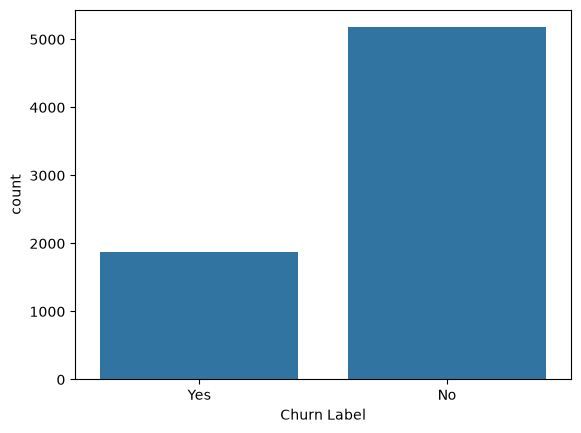

In [ ]:
sns.countplot(data=df, x="Churn Label")

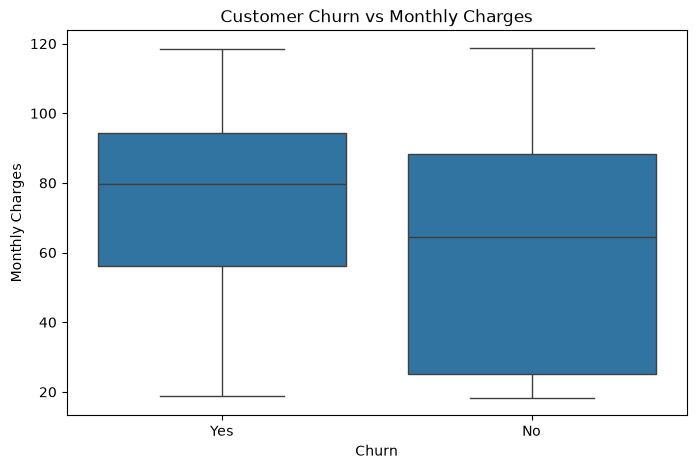

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Churn Label", y="Monthly Charges")

plt.title("Customer Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

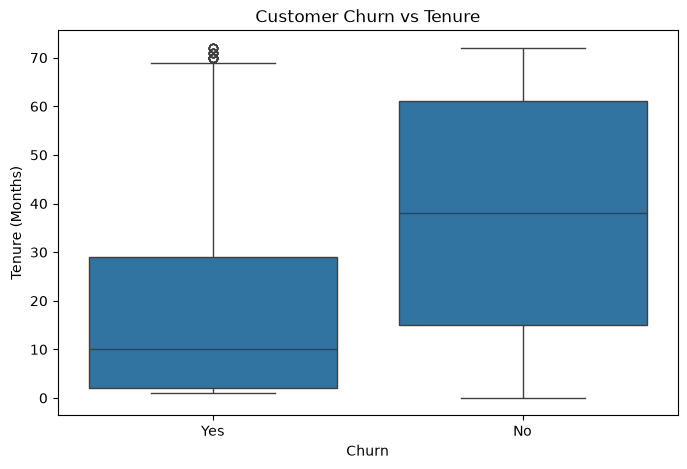

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Churn Label", y="Tenure Months")

plt.title("Customer Churn vs Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

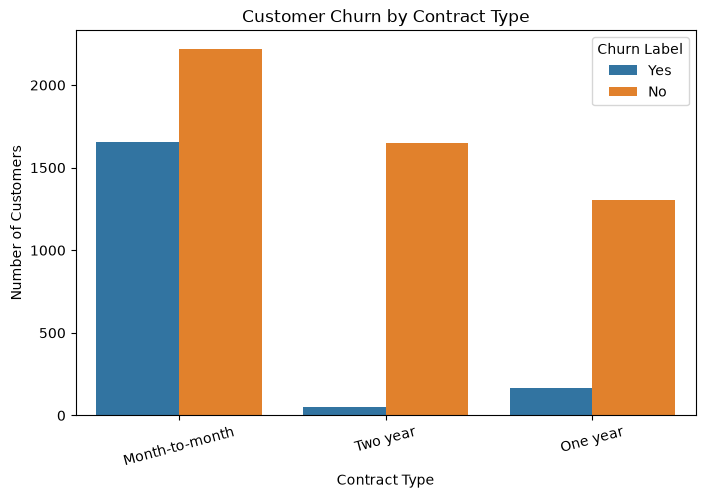

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Contract", hue="Churn Label")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
df.dtypes

CustomerID               str
Count                  int64
Country                  str
State                    str
City                     str
Zip Code               int64
Lat Long                 str
Latitude             float64
Longitude            float64
Gender                   str
Senior Citizen           str
Partner                  str
Dependents               str
Tenure Months          int64
Phone Service            str
Multiple Lines           str
Internet Service         str
Online Security          str
Online Backup            str
Device Protection        str
Tech Support             str
Streaming TV             str
Streaming Movies         str
Contract                 str
Paperless Billing        str
Payment Method           str
Monthly Charges      float64
Total Charges            str
Churn Label              str
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason             str
dtype: object

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

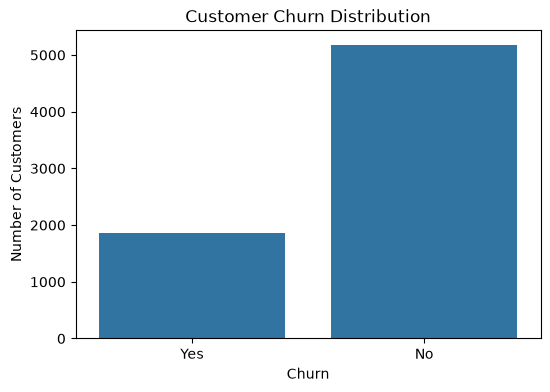

In [ ]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn Label")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [ ]:
import matplotlib.pyplot as plt

print("Matplotlib imported successfully!")

Matplotlib imported successfully!


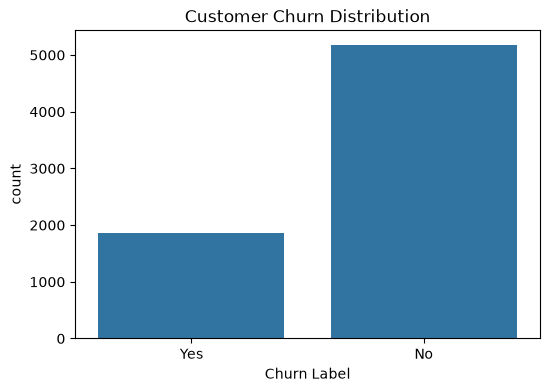

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn Label")
plt.title("Customer Churn Distribution")
plt.show()

In [ ]:
df["Churn Label"].head()

0    Yes
1    Yes
2    Yes
3    Yes
4    Yes
Name: Churn Label, dtype: str

In [ ]:
type(df)

pandas.DataFrame

In [ ]:
print(df.columns.tolist())

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [ ]:
df["Churn Label"].unique()

<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

In [ ]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
import os

print(os.listdir("../data"))

['WA_Fn-UseC_-Telco-Customer-Churn.csv']


In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
import os
print(os.getcwd())

c:\Users\Rajanna\Documents\Customer Churn Prediction\notebooks


In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [ ]:
import pandas as pd

In [ ]:
df.columns = df.columns.str.strip()

In [ ]:
print(df.columns.tolist())

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [ ]:
df["Churn Label"].value_counts()

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

In [ ]:
for col in df.columns:
    print(repr(col))

'CustomerID'
'Count'
'Country'
'State'
'City'
'Zip Code'
'Lat Long'
'Latitude'
'Longitude'
'Gender'
'Senior Citizen'
'Partner'
'Dependents'
'Tenure Months'
'Phone Service'
'Multiple Lines'
'Internet Service'
'Online Security'
'Online Backup'
'Device Protection'
'Tech Support'
'Streaming TV'
'Streaming Movies'
'Contract'
'Paperless Billing'
'Payment Method'
'Monthly Charges'
'Total Charges'
'Churn Label'
'Churn Value'
'Churn Score'
'CLTV'
'Churn Reason'


In [ ]:
print(df.shape)

(7043, 33)


In [ ]:
print(df.columns.tolist())

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [ ]:
print(df.columns.tolist())

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [ ]:
df.tail()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
7038,2569-WGERO,1,United States,California,Landers,92285,"34.341737, -116.539416",34.341737,-116.539416,Female,...,Two year,Yes,Bank transfer (automatic),21.15,1419.4,No,0,45,5306,NaN
7039,6840-RESVB,1,United States,California,Adelanto,92301,"34.667815, -117.536183",34.667815,-117.536183,Male,...,One year,Yes,Mailed check,84.80,1990.5,No,0,59,2140,NaN
7040,2234-XADUH,1,United States,California,Amboy,92304,"34.559882, -115.637164",34.559882,-115.637164,Female,...,One year,Yes,Credit card (automatic),103.20,7362.9,No,0,71,5560,NaN
7041,4801-JZAZL,1,United States,California,Angelus Oaks,92305,"34.1678, -116.86433",34.167800,-116.864330,Female,...,Month-to-month,Yes,Electronic check,29.60,346.45,No,0,59,2793,NaN
7042,3186-AJIEK,1,United States,California,Apple Valley,92308,"34.424926, -117.184503",34.424926,-117.184503,Male,...,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No,0,38,5097,NaN


In [ ]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [ ]:
df.columns

Index(['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code',
       'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen',
       'Partner', 'Dependents', 'Tenure Months', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method',
       'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value',
       'Churn Score', 'CLTV', 'Churn Reason'],
      dtype='str')

In [ ]:
df.shape

(7043, 33)

In [ ]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [ ]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")


In [ ]:
import pandas as pd